# 7. Model Evaluation and Comparison / Model Değerlendirme ve Karşılaştırma

**English theory:** [Classification](../Classification.md) · **Türkçe teori:** [Sınıflandırma](../Classification.tr.md) · [Notebook index / dizin](../README.md)

Compare six classifier families on identical training folds, select one with CV and explain its final mistakes using a confusion matrix, ROC and precision–recall curves.

**Türkçe:** Altı algoritmayı aynı katlarda karşılaştırıp test verisine göre seçim yapmadan sonuçlarını değerlendireceğiz.

Run **Restart Kernel → Run All** to reproduce every output. Each notebook starts from raw local data and has no dependency on another notebook's variables. Saved tables and figures are actual executed outputs.

**Türkçe:** Sonuçları yeniden üretmek için çekirdeği yeniden başlatıp bütün hücreleri sırayla çalıştırın. Veri dosyaları repoda bulunur; başka bir notebook'un önceden çalıştırılması gerekmez.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, JSON

# Works when launched from this folder, Classification/, or the repository root.
candidates = [Path.cwd(), *Path.cwd().parents]
CLASSIFICATION_DIR = next(
    folder for base in candidates for folder in (base, base / "Classification")
    if (folder / "Classification.md").is_file()
    and (folder / "datasets" / "data.csv").is_file()
)
SEED = 42
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_columns", 12)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
versions = {"Python": platform.python_version(), "NumPy": np.__version__,
            "pandas": pd.__version__, "SciPy": scipy.__version__,
            "scikit-learn": sklearn.__version__, "Matplotlib": matplotlib.__version__}
display(pd.Series(versions, name="Environment"))

Python          3.10.11
NumPy            1.26.4
pandas            2.3.3
SciPy            1.13.1
scikit-learn      1.7.2
Matplotlib       3.10.9
Name: Environment, dtype: object

## Data and evaluation protocol / Veri ve ölçüm düzeni

The target is `B → 0`, `M → 1`. All six tabular classifiers use the **same stratified 80/20 split** (`random_state=42`), so their training CV scores can be compared. The final 114 rows are held out. Hyperparameters are chosen with five-fold CV **inside the 455 training rows**. A scaler belongs in a pipeline so each fold learns its own training minimum and maximum. Trees and GaussianNB do not need scaling.

**Türkçe:** Önce eğitim/test ayrımı yapılır. Ölçekleme ve model seçimi yalnız eğitim verisinden öğrenilir. Test verisi K, C veya derinlik seçmek için kullanılmaz. Eski notlardaki farklı ayrımla üretilmiş örnek yüzdeler bu çalıştırmayla birebir aynı olmak zorunda değildir.

In [2]:
from sklearn.model_selection import train_test_split, StratifiedKFold

frame = pd.read_csv(CLASSIFICATION_DIR / "datasets" / "data.csv")
X = frame.drop(columns=["id", "diagnosis", "Unnamed: 32"])
y = frame["diagnosis"].map({"B": 0, "M": 1})
assert X.shape == (569, 30) and y.notna().all() and X.notna().all().all()
assert not X.columns.isin(["id", "diagnosis"]).any()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
assert set(X_train.index).isdisjoint(X_test.index)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
display(pd.DataFrame({"all": y.value_counts(), "train": y_train.value_counts(),
                      "test": y_test.value_counts()}).rename(index={0: "Benign (0)", 1: "Malignant (1)"}))
display(X_train.head(3))
print(f"Train: {X_train.shape}; held-out test: {X_test.shape}")

,all,train,test
diagnosis,,,
Benign (0),357,285,72
Malignant (1),212,170,42


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,...,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
10,16.02,23.24,102.70,797.8,0.08206,0.06669,...,0.11810,0.1551,0.1459,0.09975,0.2948,0.08452
170,12.32,12.39,78.85,464.1,0.10280,0.06981,...,0.13850,0.1266,0.1242,0.09391,0.2827,0.06771
407,12.85,21.37,82.63,514.5,0.07551,0.08316,...,0.09402,0.1936,0.1838,0.05601,0.2488,0.08151


Train: (455, 30); held-out test: (114, 30)


## Compare on training folds / Eğitim katlarında karşılaştır

These are fixed, modest configurations rather than six exhaustive hyperparameter searches. Therefore this table compares **these implementations**, not the best attainable performance of each family. Mean CV accuracy chooses the final model. Fold SD describes variation across folds; the folds overlap in training data, so it is not a confidence interval.

**Türkçe:** KNN veya SVM notebook'undaki ayrı aramalarla bu tablo aynı deney değildir. Burada her aile için önceden belirlenmiş bir ayar vardır; son test başarısı kazananı seçmek için kullanılmaz.

,model,CV_accuracy,CV_accuracy_SD,CV_macro_f1
0,"SVM (RBF, C=1)",0.975824,0.008223,0.973975
1,KNN (K=5),0.971429,0.022628,0.969016
2,Logistic Regression,0.967033,0.015541,0.963954
3,Random Forest (200 trees),0.962637,0.014906,0.959714
4,Gaussian Naive Bayes,0.940659,0.026556,0.935907
5,Decision Tree (depth=4),0.920879,0.038320,0.913968


Selected using training CV: SVM (RBF, C=1)


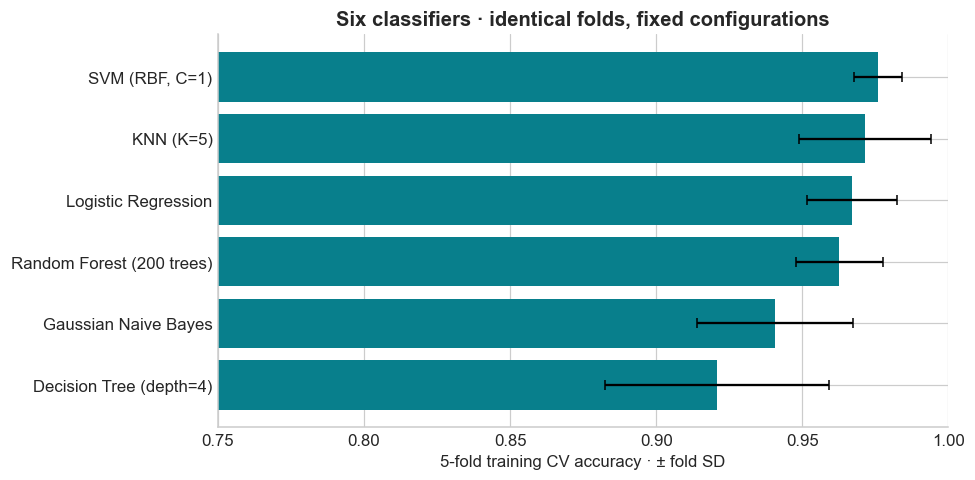

In [3]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, cross_val_predict
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)

candidates = {
    "Logistic Regression": make_pipeline(MinMaxScaler(), LogisticRegression(max_iter=3000, random_state=SEED)),
    "KNN (K=5)": make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=5)),
    "SVM (RBF, C=1)": make_pipeline(MinMaxScaler(), SVC(C=1, kernel="rbf", random_state=SEED)),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree (depth=4)": DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Random Forest (200 trees)": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
}
rows = []
for name, estimator in candidates.items():
    score = cross_validate(estimator, X_train, y_train, cv=cv, n_jobs=1,
                           scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
                           error_score="raise")
    rows.append({"model": name, "CV_accuracy": score["test_accuracy"].mean(),
                 "CV_accuracy_SD": score["test_accuracy"].std(),
                 "CV_macro_f1": score["test_macro_f1"].mean()})
comparison = pd.DataFrame(rows).sort_values("CV_accuracy", ascending=False).reset_index(drop=True)
display(comparison)
selected_name = comparison.iloc[0]["model"]
selected = clone(candidates[selected_name])
print("Selected using training CV:", selected_name)

plot = comparison.sort_values("CV_accuracy")
plt.barh(plot.model, plot.CV_accuracy, xerr=plot.CV_accuracy_SD, color="#087F8C", capsize=3)
plt.xlabel("5-fold training CV accuracy · ± fold SD")
plt.xlim(.75, 1)
plt.title("Six classifiers · identical folds, fixed configurations")
plt.tight_layout()
plt.show()

## A threshold is also a learned choice / Eşik de öğrenilen bir seçimdir

Obtain out-of-fold scores on **training rows**: every score comes from a model that did not fit that row. Choose the threshold with highest precision among thresholds reaching at least `0.95` training OOF recall. This requirement is an educational example, not a domain recommendation. The default and this predeclared threshold are both evaluated afterward; neither is chosen using test performance.

**Türkçe:** Eşiği test ROC eğrisinden seçmek de test sızıntısıdır. Burada eşik yalnız eğitim içi tahminlerden belirlenir. Eğitimde hedeflenen recall'ın testte aynen korunması garanti değildir.

In [4]:
uses_probability = hasattr(selected, "predict_proba")
method = "predict_proba" if uses_probability else "decision_function"
oof = cross_val_predict(selected, X_train, y_train, cv=cv, method=method, n_jobs=1)
oof_scores = oof[:, 1] if uses_probability else oof
pr_precision, pr_recall, thresholds = precision_recall_curve(y_train, oof_scores)
eligible = np.flatnonzero(pr_recall[:-1] >= .95)
chosen_index = eligible[np.argmax(pr_precision[:-1][eligible])]
chosen_threshold = float(thresholds[chosen_index])
default_threshold = .5 if uses_probability else 0.0
print(f"Default threshold: {default_threshold:.4f}")
print(f"Training OOF threshold: {chosen_threshold:.4f}")
print(f"Training OOF precision={pr_precision[chosen_index]:.4f}, recall={pr_recall[chosen_index]:.4f}")

selected.fit(X_train, y_train)
raw_test_scores = getattr(selected, method)(X_test)
test_scores = raw_test_scores[:, 1] if uses_probability else raw_test_scores
default_prediction = (test_scores >= default_threshold).astype(int)
tuned_prediction = (test_scores >= chosen_threshold).astype(int)
metric_rows = []
for label, prediction in [("Default threshold", default_prediction),
                           ("Training OOF threshold", tuned_prediction)]:
    metric_rows.append({"threshold_rule": label, "accuracy": accuracy_score(y_test, prediction),
                        "balanced_accuracy": balanced_accuracy_score(y_test, prediction),
                        "precision": precision_score(y_test, prediction, zero_division=0),
                        "recall": recall_score(y_test, prediction),
                        "F1": f1_score(y_test, prediction),
                        "macro_F1": f1_score(y_test, prediction, average="macro")})
metrics = pd.DataFrame(metric_rows).set_index("threshold_rule")
display(metrics)

Default threshold: 0.0000
Training OOF threshold: -0.0263
Training OOF precision=0.9819, recall=0.9588


,accuracy,balanced_accuracy,precision,recall,F1,macro_F1
threshold_rule,,,,,,
Default threshold,0.982456,0.97619,1.0,0.952381,0.97561,0.980956
Training OOF threshold,0.982456,0.97619,1.0,0.952381,0.97561,0.980956


## Four counts, several questions / Dört sayı, farklı sorular

Rows are true classes, columns predicted classes, with `1 = malignant` as positive:
$$\begin{bmatrix}TN&FP\\FN&TP\end{bmatrix},\quad
Accuracy=\frac{TP+TN}{N},\quad Precision=\frac{TP}{TP+FP},\quad
Recall=\frac{TP}{TP+FN},\quad F1=\frac{2TP}{2TP+FP+FN}.$$

ROC uses TPR vs FPR over thresholds; ROC AUC is a ranking measure. Average precision summarizes a precision–recall curve. Neither is the accuracy at a selected threshold. Always specify the positive class.

**Türkçe:** False negative, gerçek sınıfı 1 olup 0 tahmin edilen gözlemdir. Accuracy bütün satırlara, precision pozitif tahminlere, recall gerçek pozitiflere odaklanır.

accuracy     0.982456
precision    1.000000
recall       0.952381
F1           0.975610
Name: Computed directly from confusion counts, dtype: float64

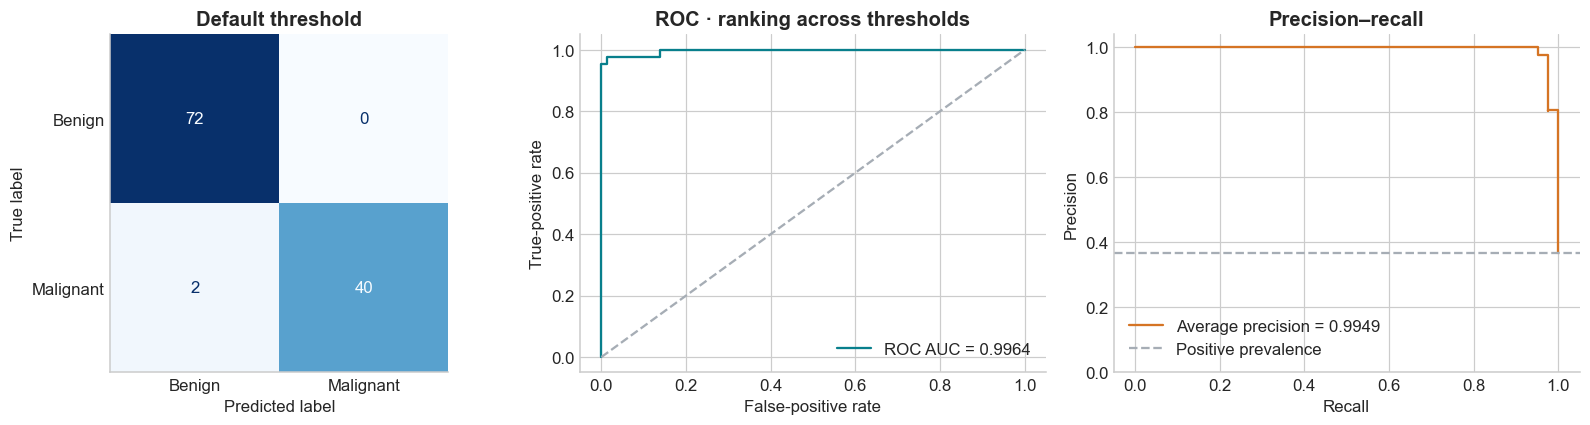

In [5]:
matrix = confusion_matrix(y_test, default_prediction, labels=[0, 1])
tn, fp, fn, tp = matrix.ravel()
manual = {"accuracy": (tp + tn) / matrix.sum(), "precision": tp / (tp + fp),
          "recall": tp / (tp + fn), "F1": 2 * tp / (2 * tp + fp + fn)}
for key, value in manual.items():
    assert np.isclose(value, metrics.loc["Default threshold", key])
display(pd.Series(manual, name="Computed directly from confusion counts"))

fpr, tpr, _ = roc_curve(y_test, test_scores)
precision, recall, _ = precision_recall_curve(y_test, test_scores)
auc = roc_auc_score(y_test, test_scores)
ap = average_precision_score(y_test, test_scores)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay(matrix, display_labels=["Benign", "Malignant"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Default threshold")
axes[0].grid(False)
axes[1].plot(fpr, tpr, color="#087F8C", label=f"ROC AUC = {auc:.4f}")
axes[1].plot([0, 1], [0, 1], "--", color="#A6ADB5")
axes[1].set(xlabel="False-positive rate", ylabel="True-positive rate", title="ROC · ranking across thresholds")
axes[1].legend(loc="lower right")
axes[2].step(recall, precision, where="post", color="#D57424", label=f"Average precision = {ap:.4f}")
axes[2].axhline(y_test.mean(), color="#A6ADB5", linestyle="--", label="Positive prevalence")
axes[2].set(xlabel="Recall", ylabel="Precision", title="Precision–recall", ylim=(0, 1.04))
axes[2].legend(loc="lower left")
plt.tight_layout()
plt.show()

## Measured result / Ölçülen sonuç

This summary is produced by the cells above; the runner also collects it in `Classification/notebook_results.json`. A single split is an educational experiment, not a guarantee for a different dataset.

**Türkçe:** Aşağıdaki değerler bu notebook'un gerçek çıktısıdır. Farklı veri veya ayrımlarda aynı sonuç garanti edilmez.

In [6]:
results = {"chapter": 7, "train_rows": len(X_train), "test_rows": len(X_test),
           "selected_by_train_CV": selected_name, "comparison": comparison.to_dict(orient="records"),
           "default_test_accuracy": float(metrics.loc["Default threshold", "accuracy"]),
           "default_confusion_matrix": matrix.tolist(), "test_roc_auc": float(auc),
           "test_average_precision": float(ap), "training_OOF_threshold": chosen_threshold,
           "threshold_comparison": metrics.reset_index().to_dict(orient="records")}
results["versions"] = versions
display(JSON(results, expanded=True))

<IPython.core.display.JSON object>